# Prédiction du churn client — Telco Customer Churn

**Dataset :** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) — 7 043 clients d'un opérateur télécom, 21 colonnes.

**Problème :** classification binaire — prédire si un client va résilier son abonnement (`Churn = Yes/No`).

**Chaîne de traitement suivie :**

```
Data  →  EDA  →  Prétraitement  →  Transformation  →  ML  →  Évaluation  →  Déploiement
```

| Étape | Contenu |
|---|---|
| 1. Data | Chargement, structure, types |
| 2. EDA | Distribution de la cible, variables numériques et catégorielles, corrélations |
| 3. Prétraitement | Types, valeurs manquantes, doublons, valeurs aberrantes, encodage de la cible |
| 4. Transformation | Feature engineering, normalisation, One-Hot Encoding, split train/test |
| 5. ML | Régression logistique, Random Forest, Gradient Boosting, XGBoost + validation croisée + GridSearch |
| 6. Évaluation | Accuracy, Precision, Recall, F1, ROC-AUC, matrice de confusion, seuil, importance des variables |
| 7. Déploiement | Sauvegarde du pipeline, fonction de prédiction, application Streamlit |

In [14]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             precision_recall_curve)
from xgboost import XGBClassifier
import joblib

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)
RANDOM_STATE = 42

---
## 1. Data — Chargement et première inspection

In [15]:
# Fonctionne sur Kaggle (dataset ajouté au notebook) et en local (CSV dans le même dossier)
CHEMINS = [
    "/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
]
chemin = next(p for p in CHEMINS if os.path.exists(p))
df_raw = pd.read_csv(chemin)
df = df_raw.copy()
print("Fichier :", chemin)
print("Dimensions :", df.shape)
df.head()

Fichier : WA_Fn-UseC_-Telco-Customer-Churn.csv
Dimensions : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


**Observations :**
- 7 043 lignes, 21 colonnes : 1 identifiant (`customerID`), 19 variables explicatives, 1 cible (`Churn`).
- `TotalCharges` est de type `object` alors qu'il devrait être numérique → à corriger au prétraitement.
- `SeniorCitizen` est codée 0/1 alors que les autres variables binaires sont en Yes/No.

In [18]:
# Modalités de chaque variable catégorielle
for col in df.select_dtypes("object").columns.drop("customerID"):
    print(f"{col:18s} {df[col].nunique():>4} modalités : {list(df[col].unique())}")

gender                2 modalités : ['Female', 'Male']
Partner               2 modalités : ['Yes', 'No']
Dependents            2 modalités : ['No', 'Yes']
PhoneService          2 modalités : ['No', 'Yes']
MultipleLines         3 modalités : ['No phone service', 'No', 'Yes']
InternetService       3 modalités : ['DSL', 'Fiber optic', 'No']
OnlineSecurity        3 modalités : ['No', 'Yes', 'No internet service']
OnlineBackup          3 modalités : ['Yes', 'No', 'No internet service']
DeviceProtection      3 modalités : ['No', 'Yes', 'No internet service']
TechSupport           3 modalités : ['No', 'Yes', 'No internet service']
StreamingTV           3 modalités : ['No', 'Yes', 'No internet service']
StreamingMovies       3 modalités : ['No', 'Yes', 'No internet service']
Contract              3 modalités : ['Month-to-month', 'One year', 'Two year']
PaperlessBilling      2 modalités : ['Yes', 'No']
PaymentMethod         4 modalités : ['Electronic check', 'Mailed check', 'Bank transfer (auto

---
## 2. EDA — Analyse exploratoire
### 2.1 Variable cible

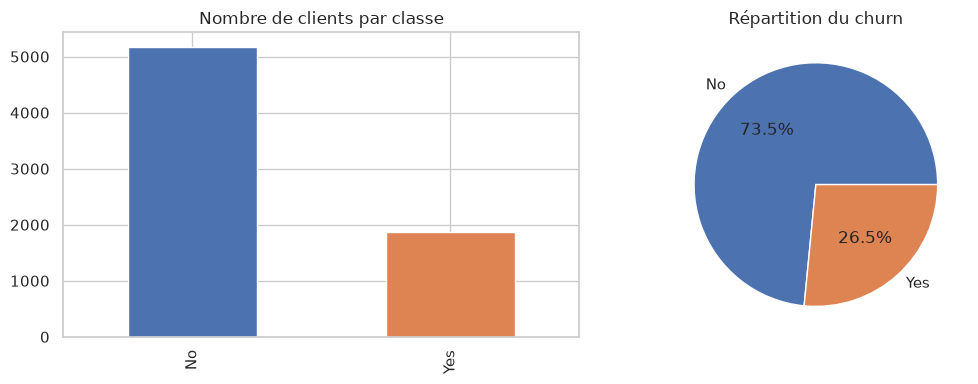

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["Churn"].value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#DD8452"])
ax[0].set_title("Nombre de clients par classe"); ax[0].set_xlabel("")
df["Churn"].value_counts(normalize=True).mul(100).plot.pie(
    ax=ax[1], autopct="%.1f%%", colors=["#4C72B0", "#DD8452"], ylabel="")
ax[1].set_title("Répartition du churn")
plt.tight_layout(); plt.show()
print(df["Churn"].value_counts(normalize=True).round(3))

La cible est **déséquilibrée** (~73 % / 27 %). L'accuracy seule sera donc trompeuse : on suivra surtout le **Recall**, le **F1** et le **ROC-AUC** de la classe *Churn = Yes*, et on utilisera `class_weight="balanced"`.

### 2.2 Variables numériques

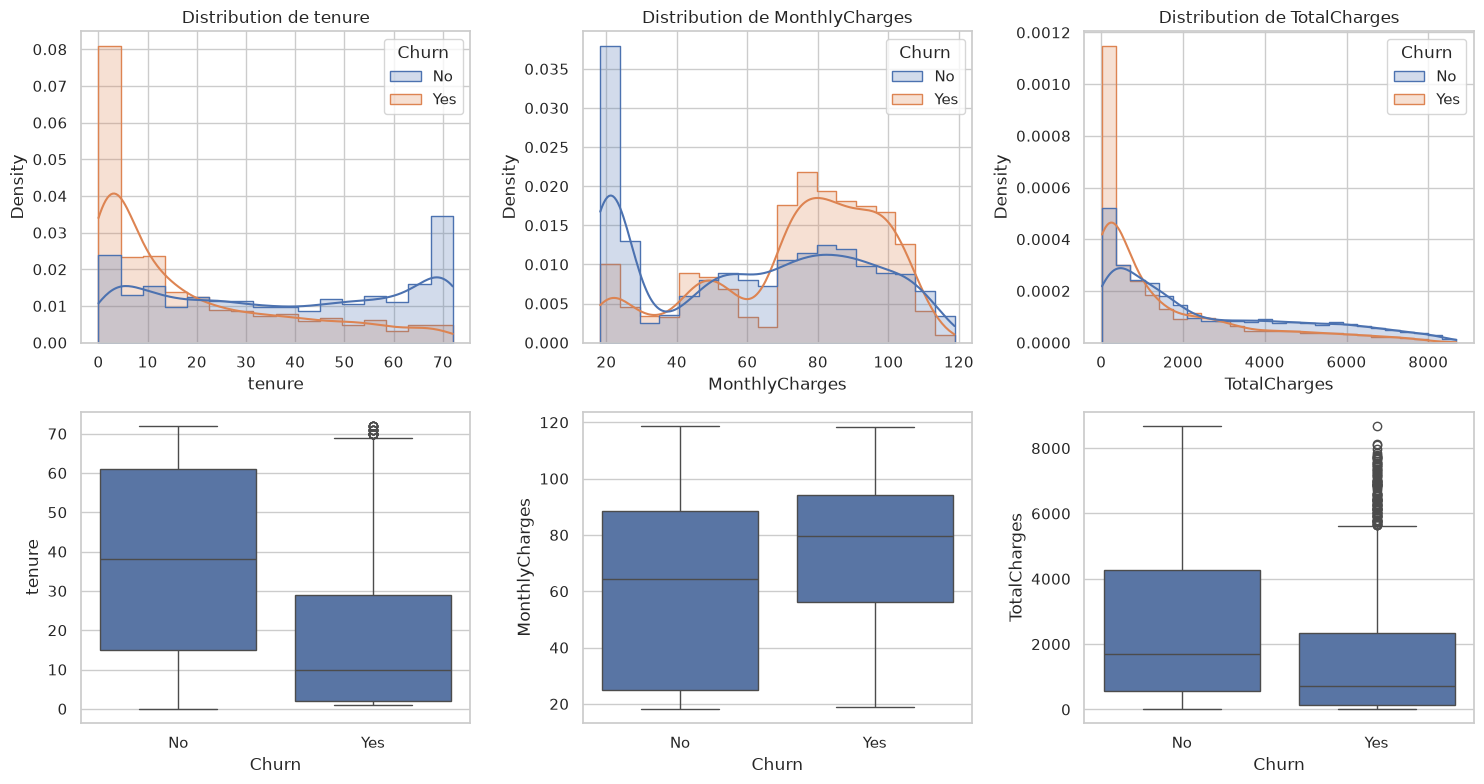

In [20]:
# conversion temporaire pour l'EDA (traitée proprement à l'étape 3)
eda = df.copy()
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"], errors="coerce")
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num_cols):
    sns.histplot(data=eda, x=col, hue="Churn", kde=True, ax=axes[0, i], element="step", stat="density", common_norm=False)
    sns.boxplot(data=eda, x="Churn", y=col, ax=axes[1, i])
    axes[0, i].set_title(f"Distribution de {col}")
plt.tight_layout(); plt.show()

In [21]:
eda.groupby("Churn")[num_cols].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1683.60
Yes,10.0,79.650,703.55


**Observations :**
- Les clients qui partent ont une **ancienneté (`tenure`) beaucoup plus faible** : le risque est maximal pendant les premiers mois.
- Ils paient des **`MonthlyCharges` plus élevés**.
- `TotalCharges` ≈ `tenure × MonthlyCharges` → forte corrélation attendue.

### 2.3 Variables catégorielles — taux de churn par modalité

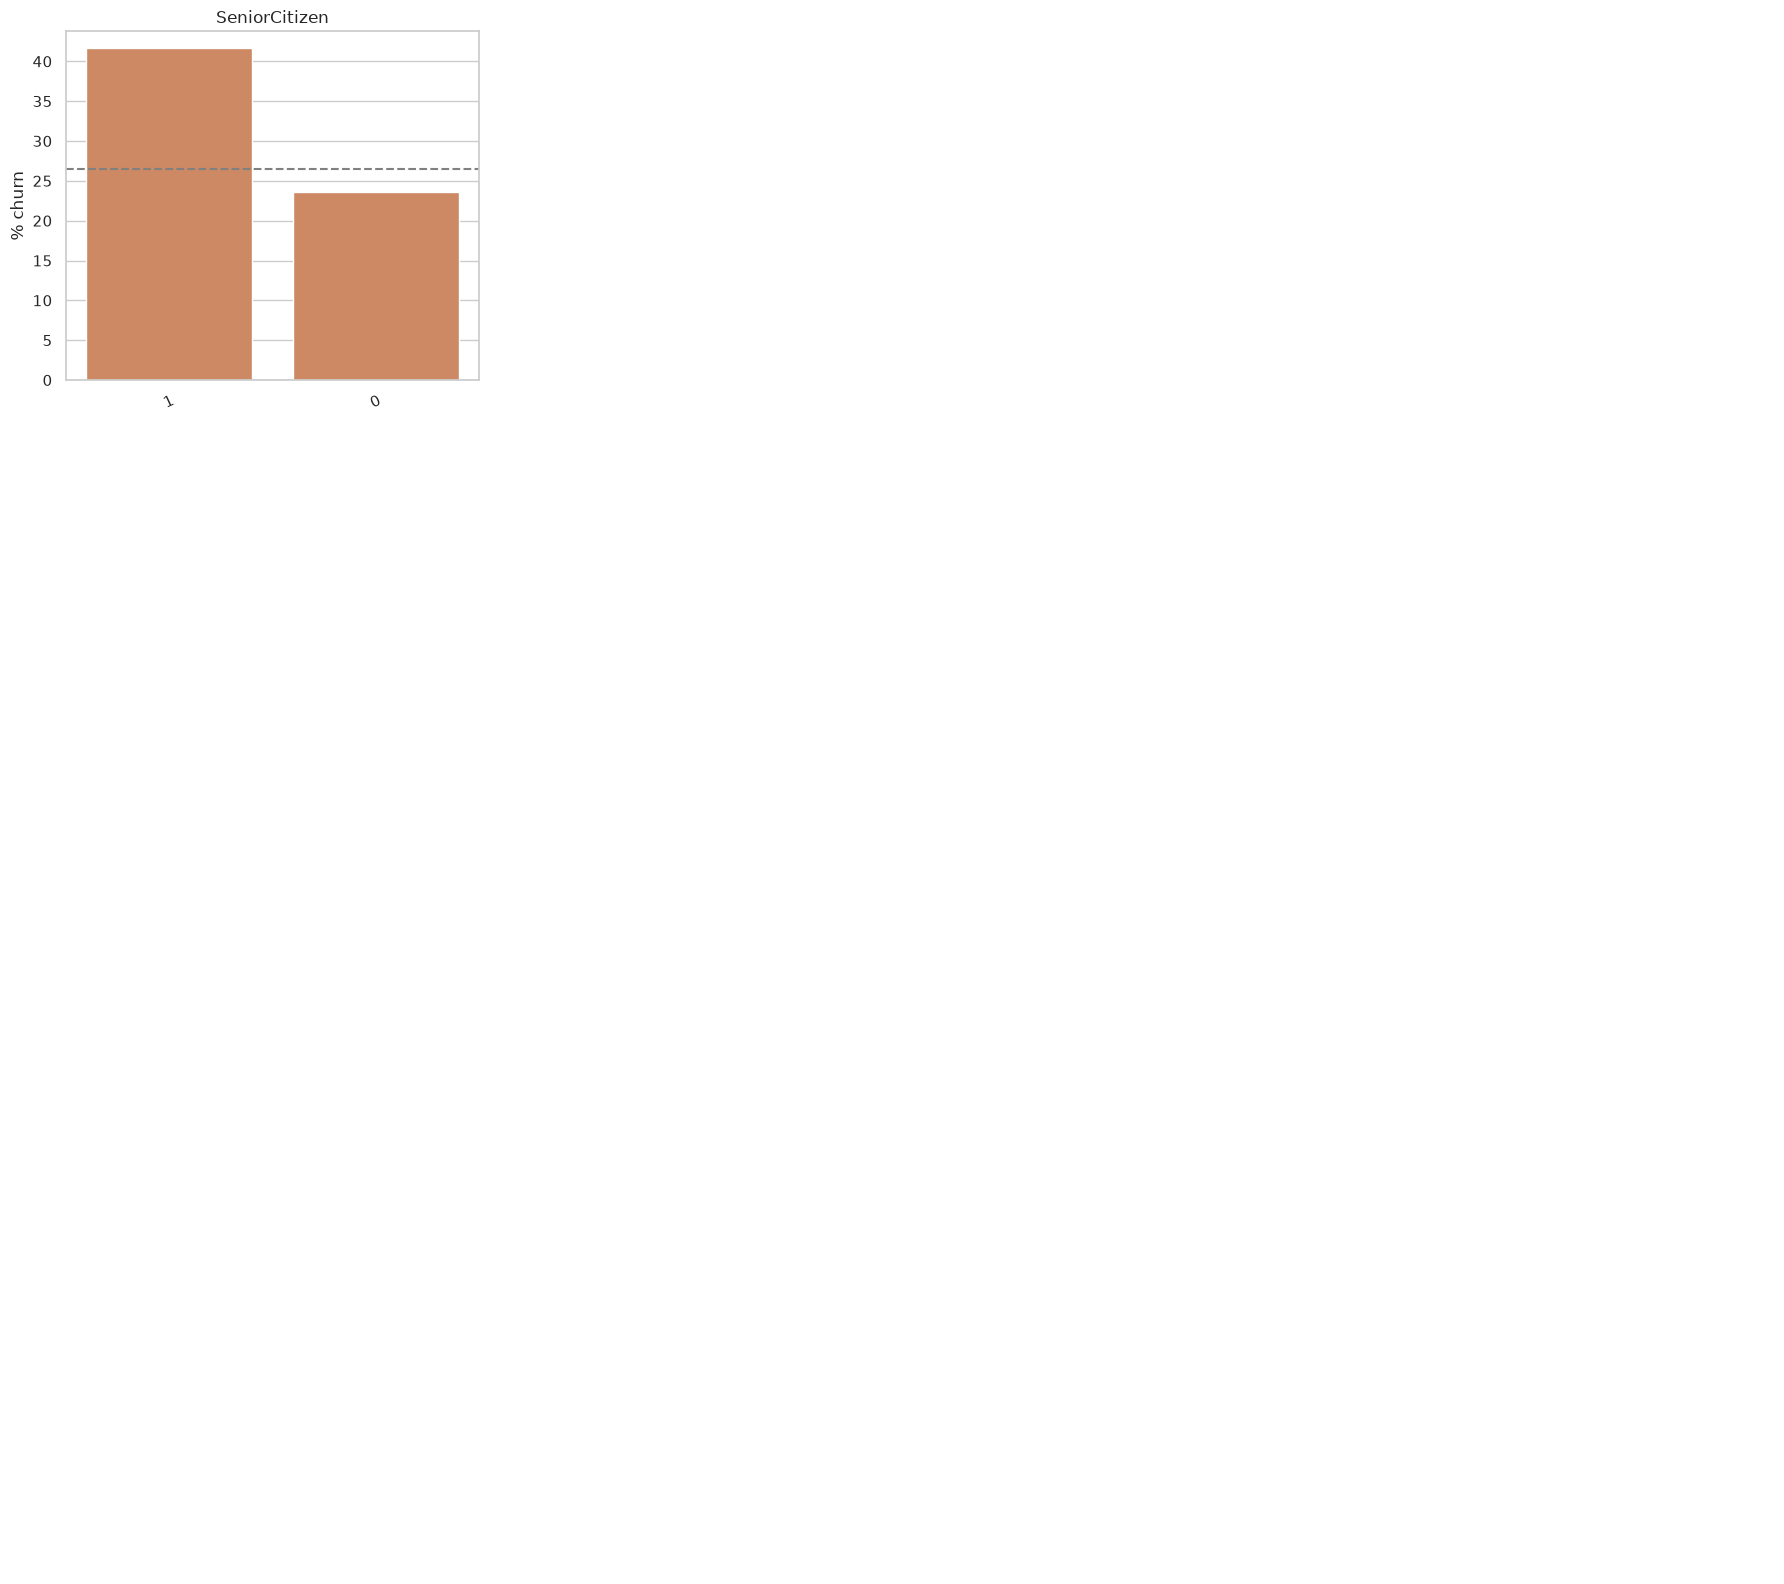

In [22]:
cat_cols = [c for c in df.columns if df[c].dtype == "object" and c not in ("customerID", "Churn", "TotalCharges")] + ["SeniorCitizen"]
eda["churn_bin"] = (eda["Churn"] == "Yes").astype(int)

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
for ax, col in zip(axes.flat, cat_cols):
    taux = eda.groupby(col)["churn_bin"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=taux.index.astype(str), y=taux.values, ax=ax, color="#DD8452")
    ax.axhline(eda["churn_bin"].mean() * 100, ls="--", c="grey")
    ax.set_title(col); ax.set_ylabel("% churn"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
for ax in axes.flat[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**Observations (ligne grise = taux moyen ≈ 26.5 %) :**
- **`Contract`** : énorme écart — *Month-to-month* ≈ 43 % de churn contre ≈ 3 % pour un contrat de 2 ans.
- **`InternetService`** : la *Fiber optic* churne beaucoup plus que le DSL.
- **`PaymentMethod`** : *Electronic check* ≈ 45 % de churn.
- L'absence de services de protection (`OnlineSecurity`, `TechSupport`) est associée à plus de churn.
- `gender` et `PhoneService` n'ont quasiment aucun effet.

### 2.4 Corrélations

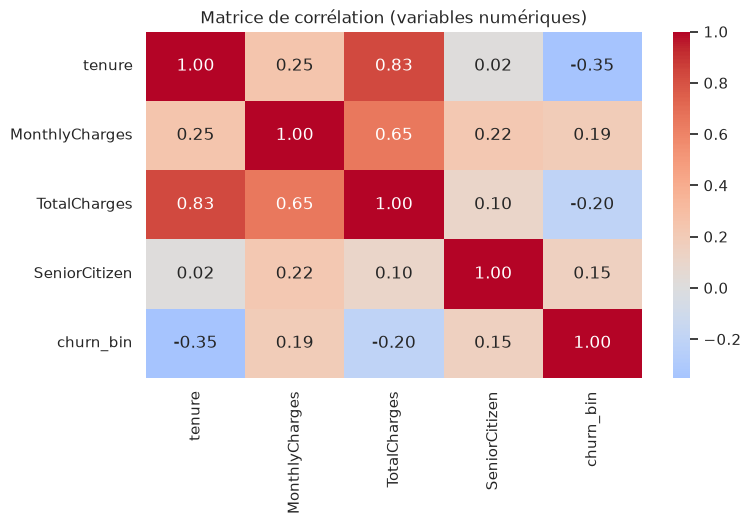

In [23]:
corr = eda[num_cols + ["SeniorCitizen", "churn_bin"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation (variables numériques)"); plt.show()

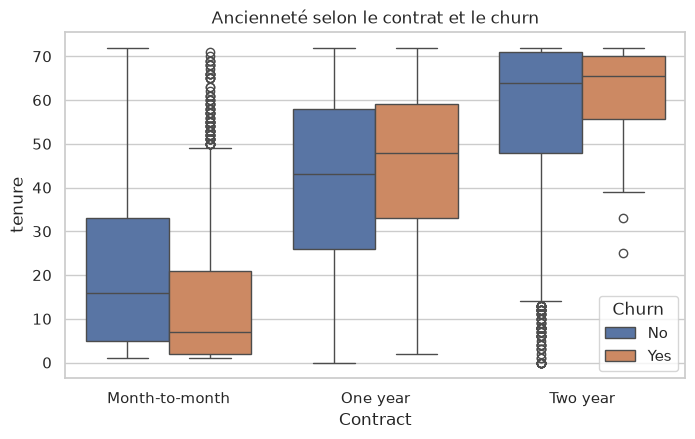

In [24]:
# Croisement tenure × contrat
sns.boxplot(data=eda, x="Contract", y="tenure", hue="Churn")
plt.title("Ancienneté selon le contrat et le churn"); plt.show()

---
## 3. Prétraitement — Nettoyage des données
### 3.1 Conversion de `TotalCharges` et valeurs manquantes

In [25]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
print("Valeurs manquantes par colonne :")
print(df.isna().sum()[df.isna().sum() > 0])
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Valeurs manquantes par colonne :
TotalCharges    11
dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Les 11 valeurs manquantes correspondent toutes à des clients avec **`tenure = 0`** (nouveaux clients pas encore facturés). La valeur logique est donc **0**, pas la moyenne.

In [26]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Valeurs manquantes restantes :", df.isna().sum().sum())

Valeurs manquantes restantes : 0


### 3.2 Doublons, identifiant et valeurs aberrantes

In [27]:
print("Doublons sur customerID :", df["customerID"].duplicated().sum())
df = df.drop(columns="customerID")
print("Lignes entièrement dupliquées (sans l'ID) :", df.duplicated().sum())

Doublons sur customerID : 0
Lignes entièrement dupliquées (sans l'ID) : 22


Les quelques lignes identiques sans l'ID sont des clients différents qui ont le même profil (ce ne sont pas de vraies erreurs) : on les **conserve**.

In [28]:
# Détection des valeurs aberrantes par la règle de l'IQR
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:15s} -> {n_out} valeurs aberrantes")

tenure          -> 0 valeurs aberrantes
MonthlyCharges  -> 0 valeurs aberrantes
TotalCharges    -> 0 valeurs aberrantes


Aucune valeur aberrante selon l'IQR : pas de traitement nécessaire.

### 3.3 Harmonisation des modalités et encodage de la cible

In [29]:
# 'No internet service' / 'No phone service' signifient simplement 'No' pour ces services
cols_internet = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df[cols_internet] = df[cols_internet].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

# SeniorCitizen 0/1 -> Yes/No pour être cohérent avec les autres binaires
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Cible en 0/1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(df.shape)
df.head()

(7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


---
## 4. Transformation — Feature engineering, encodage, normalisation
### 4.1 Création de nouvelles variables

In [30]:
services = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def feature_engineering(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    # nombre de services souscrits
    data["NbServices"] = (data[services] == "Yes").sum(axis=1) + (data["InternetService"] != "No").astype(int)
    # dépense moyenne mensuelle réelle
    data["AvgCharge"] = np.where(data["tenure"] > 0, data["TotalCharges"] / data["tenure"].replace(0, 1), data["MonthlyCharges"])
    # tranche d'ancienneté
    data["TenureGroup"] = pd.cut(data["tenure"], bins=[-1, 12, 24, 48, 72],
                                 labels=["0-1an", "1-2ans", "2-4ans", "4-6ans"]).astype(str)
    # client "sans engagement" payant par chèque électronique : profil le plus à risque vu en EDA
    data["MonthlyEcheck"] = ((data["Contract"] == "Month-to-month") &
                             (data["PaymentMethod"] == "Electronic check")).map({True: "Yes", False: "No"})
    return data

df_fe = feature_engineering(df)
df_fe.groupby("TenureGroup")["Churn"].mean().sort_values(ascending=False)

TenureGroup
0-1an     0.474382
1-2ans    0.287109
2-4ans    0.203890
4-6ans    0.095132
Name: Churn, dtype: float64

### 4.2 Séparation X / y et train / test (stratifiée)

In [31]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Taux de churn train / test :", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Train : (5634, 19) | Test : (1409, 19)
Taux de churn train / test : 0.265 / 0.265


### 4.3 Pipeline de transformation

Le feature engineering, la normalisation et le One-Hot Encoding sont regroupés dans **un seul `Pipeline` scikit-learn**. Avantages :
- pas de **fuite de données** (le scaler n'apprend que sur le train, y compris dans la validation croisée) ;
- le même objet sera réutilisé tel quel pour le **déploiement**.

In [32]:
num_features = ["tenure", "MonthlyCharges", "TotalCharges", "NbServices", "AvgCharge"]
cat_features = [c for c in df_fe.columns if c not in num_features + ["Churn"]]
print("Numériques  :", num_features)
print("Catégorielles :", cat_features)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_features),
])

def make_pipeline(model):
    return Pipeline([
        ("fe", FunctionTransformer(feature_engineering)),
        ("prep", preprocessor),
        ("model", model),
    ])

# aperçu de la matrice transformée
tmp = make_pipeline(LogisticRegression()).fit(X_train, y_train)
Xt = tmp[:-1].transform(X_train)
noms_features = tmp.named_steps["prep"].get_feature_names_out()
print("Dimension après transformation :", Xt.shape)

Numériques  : ['tenure', 'MonthlyCharges', 'TotalCharges', 'NbServices', 'AvgCharge']
Catégorielles : ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup', 'MonthlyEcheck']
Dimension après transformation : (5634, 33)


---
## 5. ML — Entraînement et comparaison de modèles

On compare 4 modèles avec une **validation croisée stratifiée à 5 plis** sur le train uniquement.

In [20]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
modeles = {
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest":         RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":     GradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost":               XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                           scale_pos_weight=ratio, eval_metric="logloss",
                                           random_state=RANDOM_STATE, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
resultats_cv = {}
for nom, m in modeles.items():
    s = cross_validate(make_pipeline(m), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    resultats_cv[nom] = {k: s[f"test_{k}"].mean() for k in scoring}

res_cv = pd.DataFrame(resultats_cv).T.sort_values("roc_auc", ascending=False)
res_cv.style.format("{:.3f}").highlight_max(axis=0, color="#c6efce")

,accuracy,precision,recall,f1,roc_auc
Gradient Boosting,0.798,0.653,0.513,0.574,0.846
Régression logistique,0.748,0.517,0.798,0.627,0.846
Random Forest,0.768,0.545,0.763,0.635,0.844
XGBoost,0.756,0.528,0.773,0.627,0.842


Le Gradient Boosting sans pondération a une bonne accuracy mais un **recall faible** : il rate beaucoup de clients qui partent. Les modèles pondérés (`class_weight` / `scale_pos_weight`) détectent bien plus de churners.

### 5.1 Optimisation des hyperparamètres (GridSearchCV)

On optimise la régression logistique et XGBoost en maximisant le **ROC-AUC**.

In [21]:
grid_lr = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced")),
    {"model__C": [0.01, 0.1, 1, 10], "model__penalty": ["l2"]},
    cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

grid_xgb = GridSearchCV(
    make_pipeline(XGBClassifier(scale_pos_weight=ratio, eval_metric="logloss",
                                random_state=RANDOM_STATE, n_jobs=-1)),
    {"model__n_estimators": [200, 400],
     "model__max_depth": [3, 4],
     "model__learning_rate": [0.03, 0.05],
     "model__subsample": [0.8, 1.0]},
    cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

print("LogReg  - meilleurs params :", grid_lr.best_params_, "| AUC CV =", round(grid_lr.best_score_, 4))
print("XGBoost - meilleurs params :", grid_xgb.best_params_, "| AUC CV =", round(grid_xgb.best_score_, 4))

LogReg  - meilleurs params : {'model__C': 0.1, 'model__penalty': 'l2'} | AUC CV = 0.8459
XGBoost - meilleurs params : {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8} | AUC CV = 0.848


---
## 6. Évaluation sur le jeu de test
### 6.1 Métriques

In [22]:
finaux = {
    "Régression logistique (optimisée)": grid_lr.best_estimator_,
    "XGBoost (optimisé)": grid_xgb.best_estimator_,
    "Random Forest": make_pipeline(modeles["Random Forest"]).fit(X_train, y_train),
}

def evaluer(model, X, y, seuil=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= seuil).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, proba)}

res_test = pd.DataFrame({n: evaluer(m, X_test, y_test) for n, m in finaux.items()}).T
res_test.style.format("{:.3f}").highlight_max(axis=0, color="#c6efce")

,Accuracy,Precision,Recall,F1,ROC-AUC
Régression logistique (optimisée),0.737,0.503,0.791,0.615,0.841
XGBoost (optimisé),0.750,0.519,0.805,0.631,0.847
Random Forest,0.765,0.540,0.775,0.637,0.843


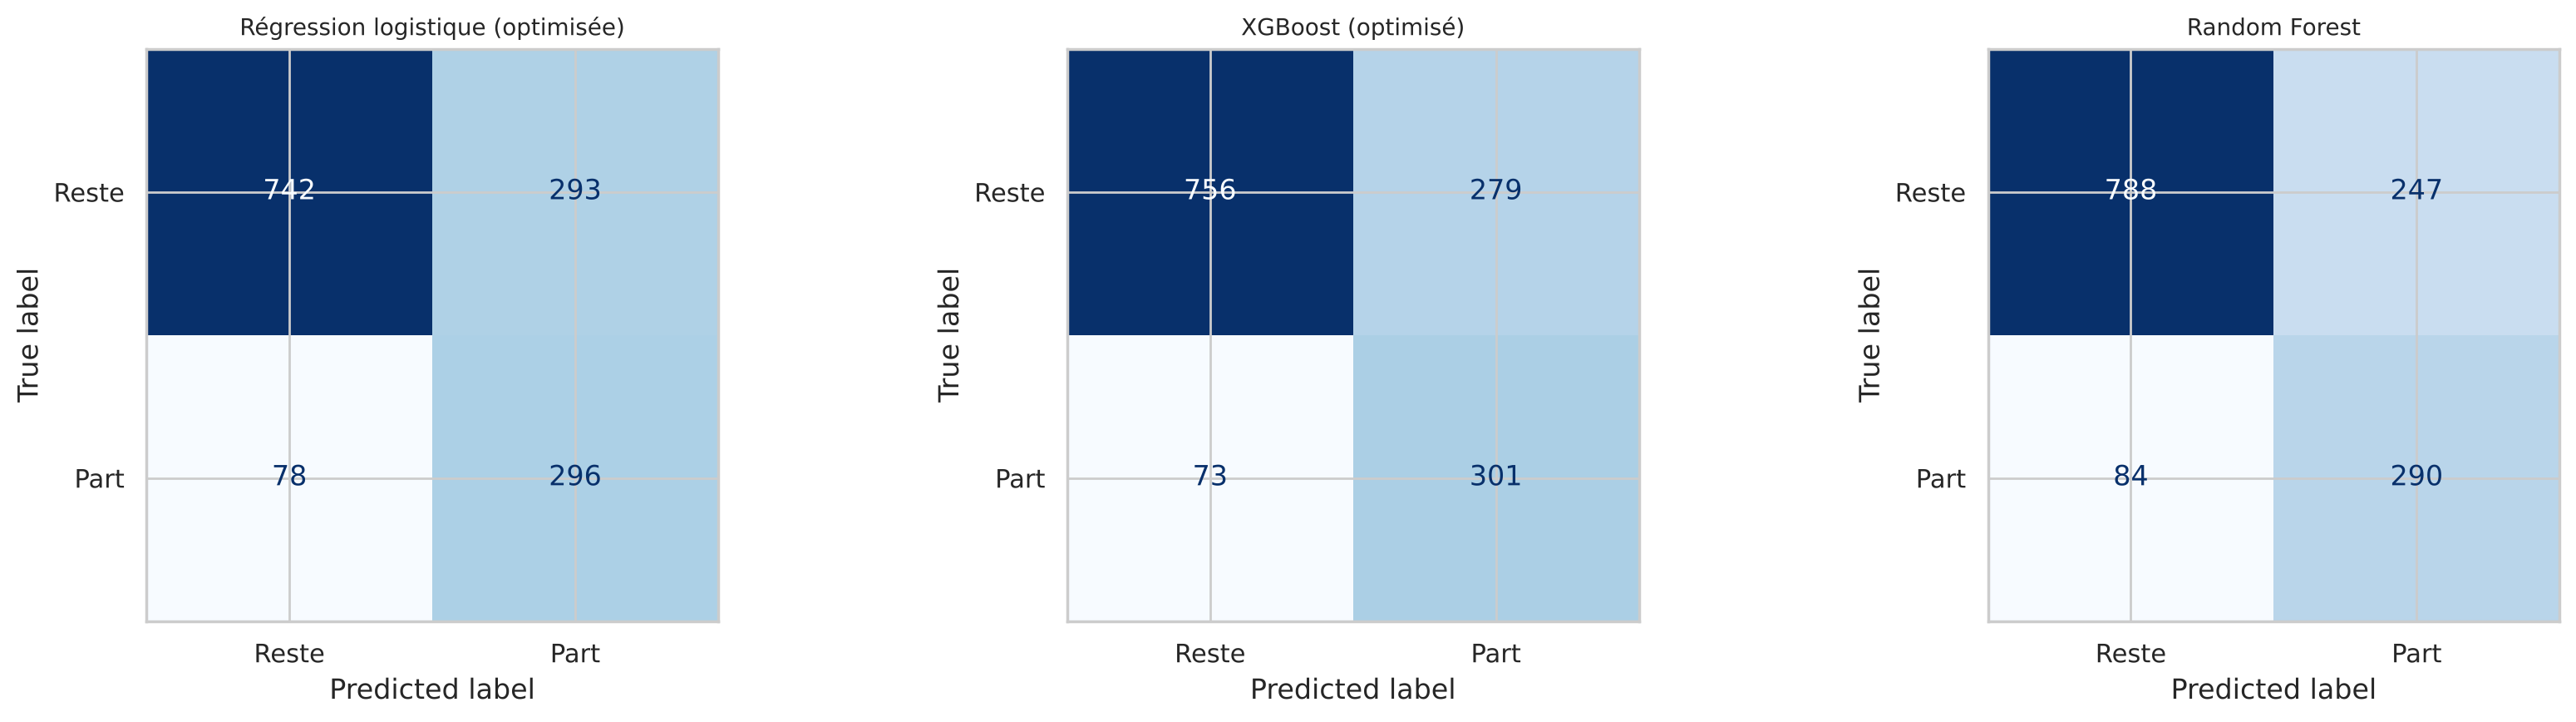

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (nom, m) in zip(axes, finaux.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["Reste", "Part"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nom, fontsize=10)
plt.tight_layout(); plt.show()

### 6.2 Courbes ROC

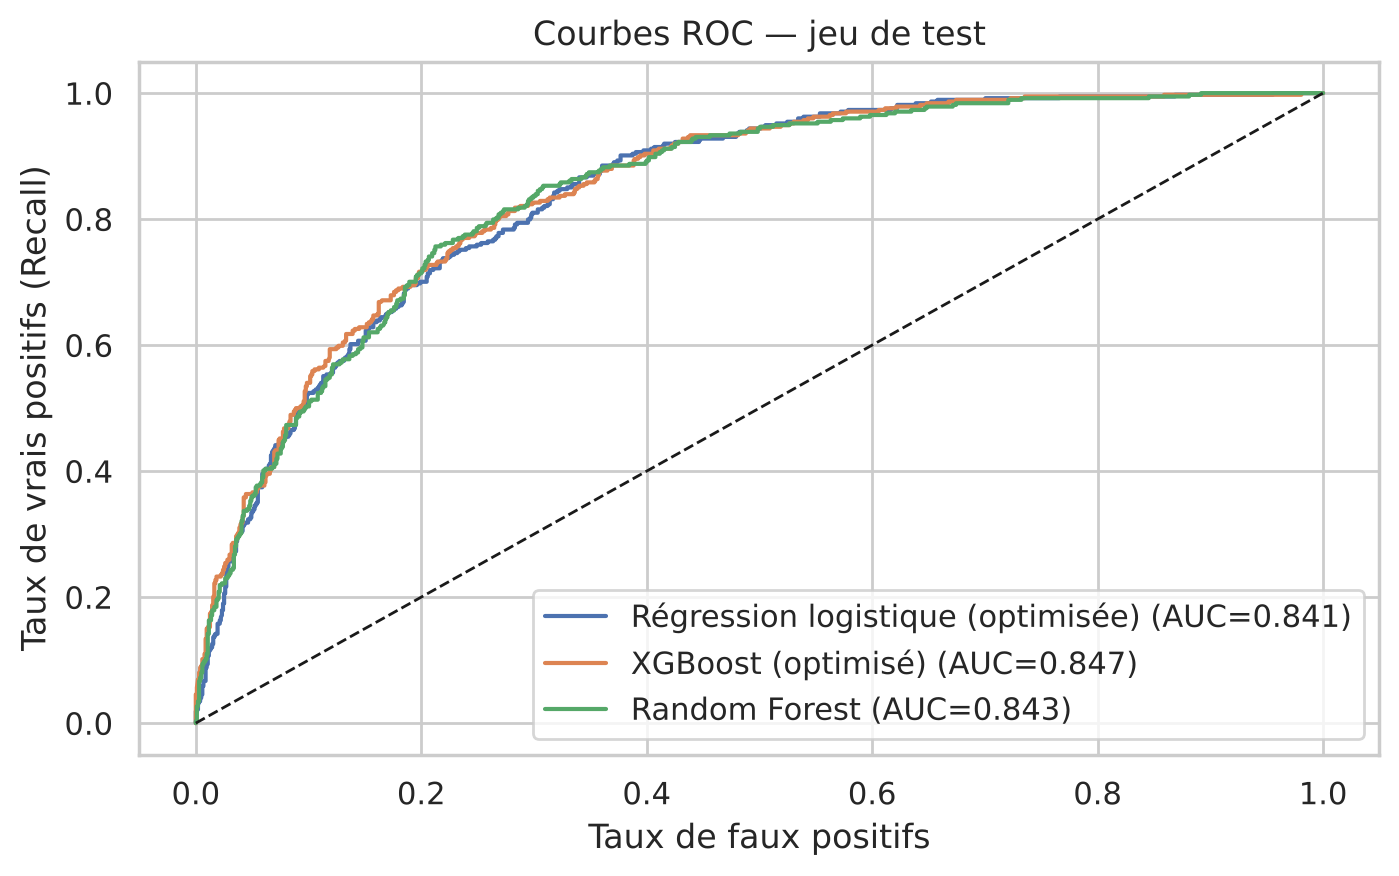

In [24]:
for nom, m in finaux.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{nom} (AUC={roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Taux de faux positifs"); plt.ylabel("Taux de vrais positifs (Recall)")
plt.title("Courbes ROC — jeu de test"); plt.legend(); plt.show()

### 6.3 Choix du modèle final et du seuil de décision

On retient le modèle avec le meilleur ROC-AUC sur le test. Le seuil 0.5 n'est pas forcément optimal : on choisit le seuil qui **maximise le F1** — **sur le train par validation croisée** pour ne pas tricher avec le test.

Modèle retenu : XGBoost (optimisé)
Seuil optimal (F1, CV train) : 0.550


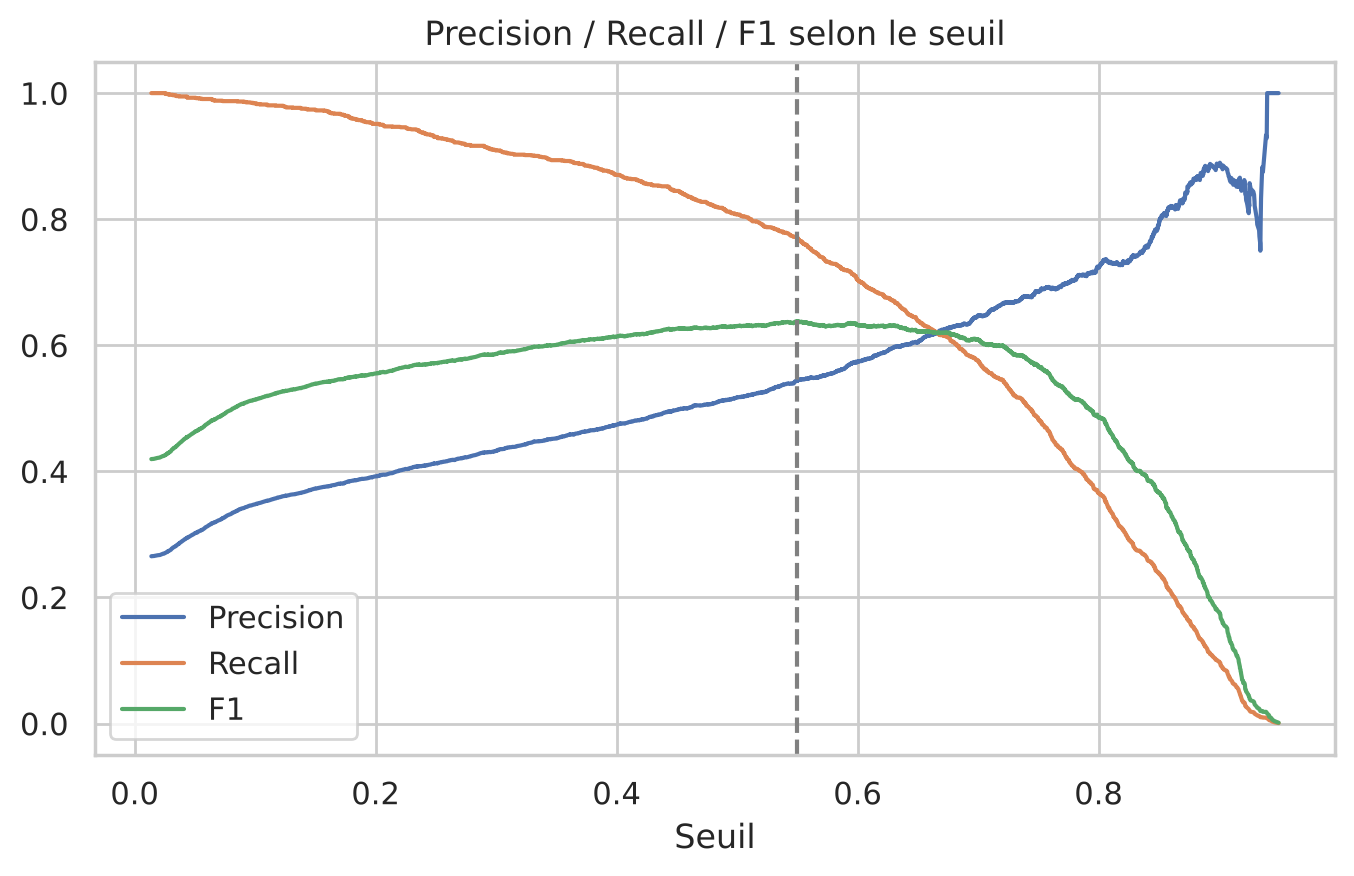

           seuil 0.5  seuil 0.55
Accuracy       0.750       0.759
Precision      0.519       0.532
Recall         0.805       0.773
F1             0.631       0.630
ROC-AUC        0.847       0.847


In [25]:
from sklearn.model_selection import cross_val_predict

nom_final = res_test["ROC-AUC"].idxmax()
modele_final = finaux[nom_final]
print("Modèle retenu :", nom_final)

proba_oof = cross_val_predict(modele_final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, seuils = precision_recall_curve(y_train, proba_oof)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
SEUIL = float(seuils[np.argmax(f1s[:-1])])
print(f"Seuil optimal (F1, CV train) : {SEUIL:.3f}")

plt.plot(seuils, prec[:-1], label="Precision"); plt.plot(seuils, rec[:-1], label="Recall")
plt.plot(seuils, f1s[:-1], label="F1"); plt.axvline(SEUIL, c="grey", ls="--")
plt.xlabel("Seuil"); plt.title("Precision / Recall / F1 selon le seuil"); plt.legend(); plt.show()

print(pd.DataFrame({"seuil 0.5": evaluer(modele_final, X_test, y_test),
                    f"seuil {SEUIL:.2f}": evaluer(modele_final, X_test, y_test, SEUIL)}).round(3))

In [26]:
pred_final = (modele_final.predict_proba(X_test)[:, 1] >= SEUIL).astype(int)
print(classification_report(y_test, pred_final, target_names=["Reste (0)", "Part (1)"]))

              precision    recall  f1-score   support

   Reste (0)       0.90      0.75      0.82      1035
    Part (1)       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



### 6.4 Importance des variables

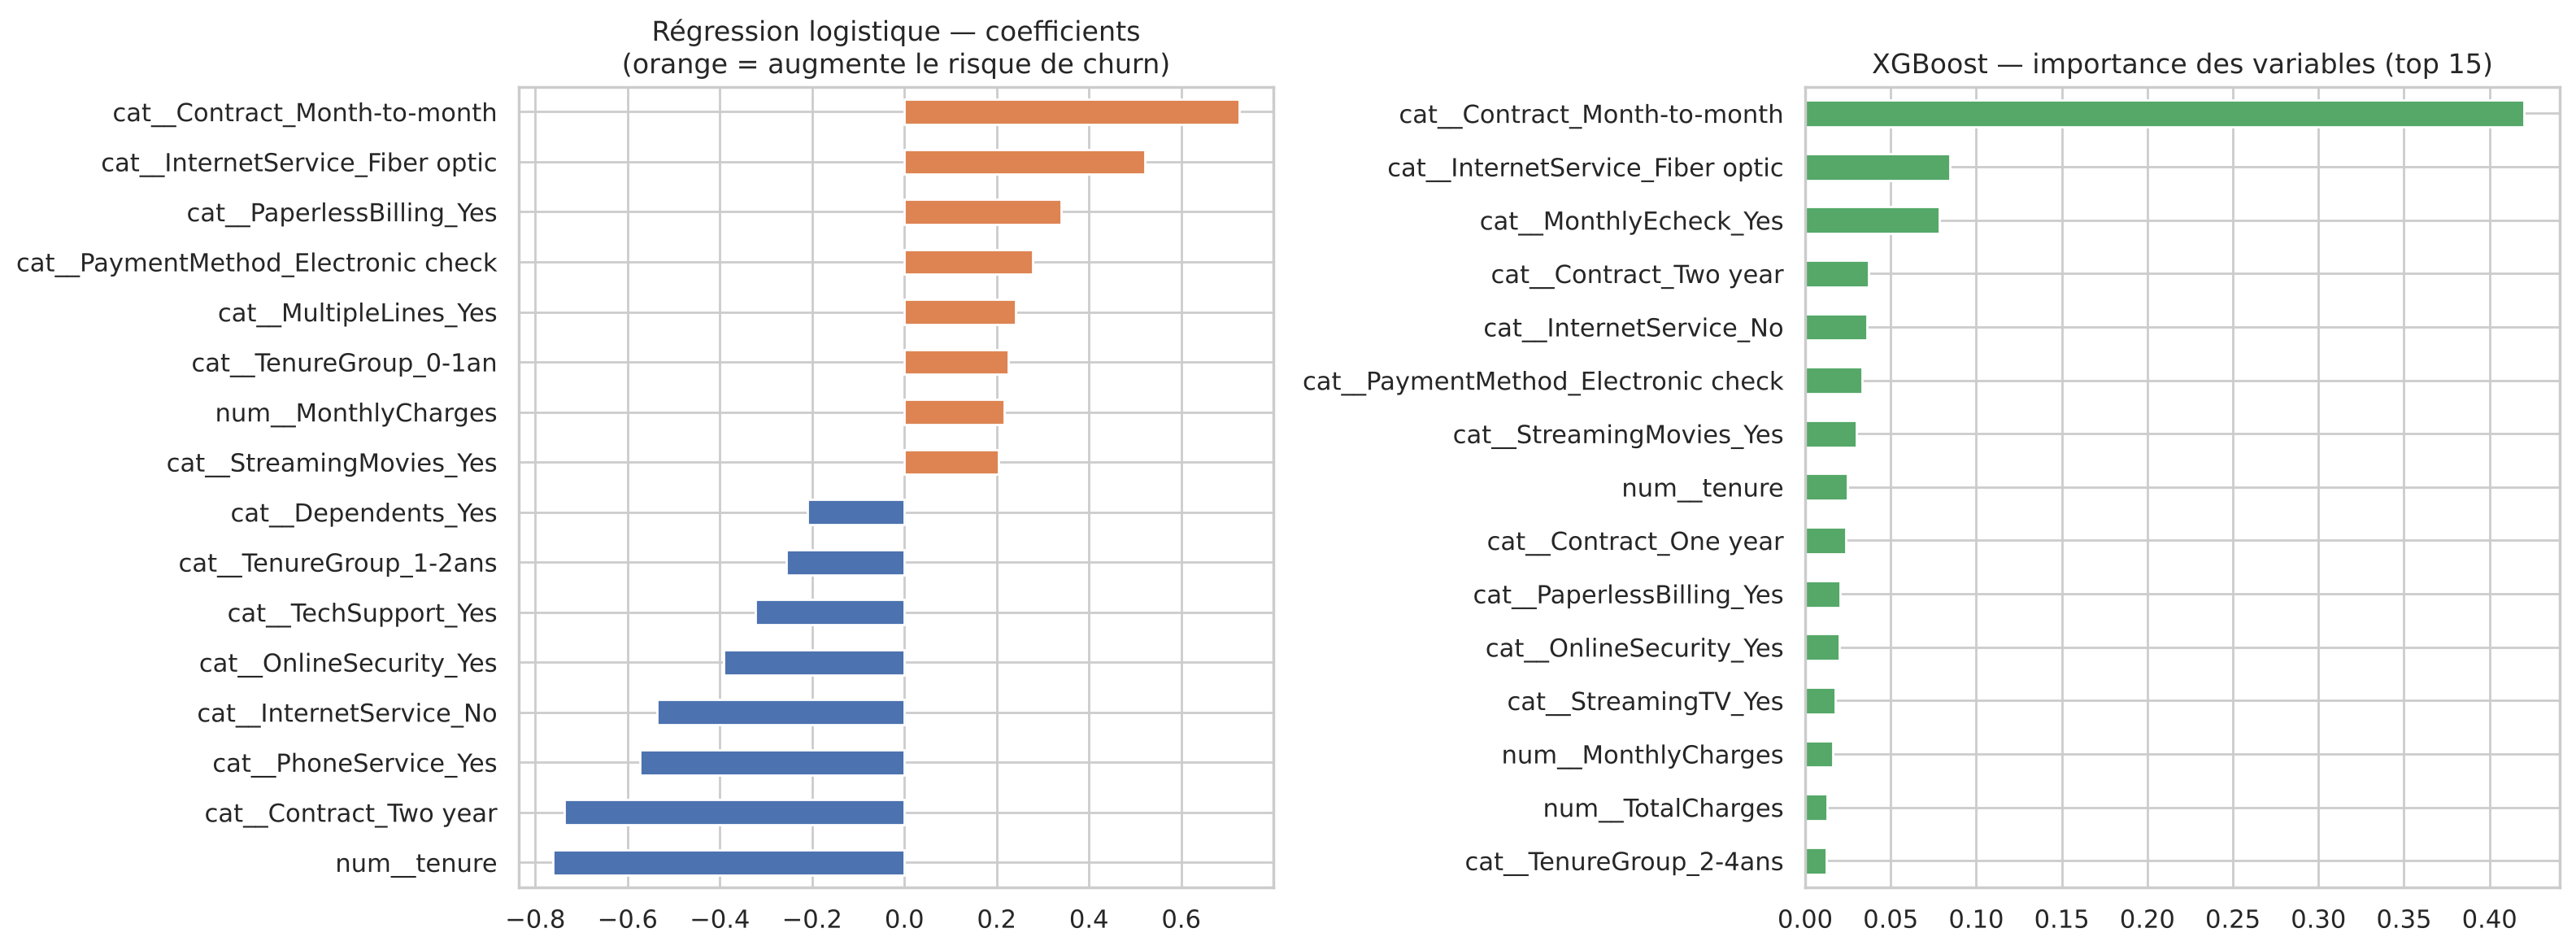

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Coefficients de la régression logistique
lr = grid_lr.best_estimator_
coefs = pd.Series(lr.named_steps["model"].coef_[0],
                  index=lr.named_steps["prep"].get_feature_names_out()).sort_values()
pd.concat([coefs.head(8), coefs.tail(8)]).plot.barh(ax=axes[0], color=np.where(pd.concat([coefs.head(8), coefs.tail(8)]) > 0, "#DD8452", "#4C72B0"))
axes[0].set_title("Régression logistique — coefficients\n(orange = augmente le risque de churn)")

# Importance XGBoost
xgb = grid_xgb.best_estimator_
imp = pd.Series(xgb.named_steps["model"].feature_importances_,
                index=xgb.named_steps["prep"].get_feature_names_out()).sort_values().tail(15)
imp.plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("XGBoost — importance des variables (top 15)")
plt.tight_layout(); plt.show()

**Conclusions :**
- Les facteurs principaux du churn sont le **type de contrat** (mensuel), une **faible ancienneté**, la **fibre optique**, le paiement par **chèque électronique** et l'absence de **support technique / sécurité en ligne**.
- Un contrat d'1 ou 2 ans et une longue ancienneté protègent fortement contre le départ.
- Recommandation métier : cibler les nouveaux clients en contrat mensuel avec des offres de migration vers un contrat annuel et des services de support inclus.

---
## 7. Déploiement
### 7.1 Sauvegarde du pipeline complet

On sauvegarde **tout le pipeline** (feature engineering + transformation + modèle) et le seuil : il suffit ensuite de lui donner les données brutes d'un client.

In [28]:
os.makedirs("model", exist_ok=True)
joblib.dump({"pipeline": modele_final, "seuil": SEUIL, "nom": nom_final}, "model/churn_model.joblib")
print("Modèle sauvegardé :", os.path.getsize("model/churn_model.joblib") // 1024, "Ko")

Modèle sauvegardé : 245 Ko


### 7.2 Fonction de prédiction et test sur un nouveau client

In [29]:
artefact = joblib.load("model/churn_model.joblib")

def predire_churn(client: dict) -> dict:
    """Prend les informations brutes d'un client et renvoie la probabilité de churn."""
    X_new = pd.DataFrame([client])
    X_new["TotalCharges"] = pd.to_numeric(X_new["TotalCharges"], errors="coerce").fillna(0)
    proba = float(artefact["pipeline"].predict_proba(X_new)[0, 1])
    return {"probabilite_churn": round(proba, 3),
            "prediction": "Va partir" if proba >= artefact["seuil"] else "Va rester"}

client_risque = {
    "gender": "Female", "SeniorCitizen": "No", "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.5, "TotalCharges": 191.0,
}
client_fidele = {**client_risque, "tenure": 60, "InternetService": "DSL", "OnlineSecurity": "Yes",
                 "TechSupport": "Yes", "Contract": "Two year", "PaymentMethod": "Credit card (automatic)",
                 "MonthlyCharges": 65.0, "TotalCharges": 3900.0}

print("Client à risque :", predire_churn(client_risque))
print("Client fidèle   :", predire_churn(client_fidele))

Client à risque : {'probabilite_churn': 0.904, 'prediction': 'Va partir'}
Client fidèle   : {'probabilite_churn': 0.052, 'prediction': 'Va rester'}


### 7.3 Application web Streamlit

La cellule suivante génère `app.py`. Pour lancer l'application :
```bash
pip install -r requirements.txt
streamlit run app.py
```
Elle peut ensuite être déployée gratuitement sur **Streamlit Community Cloud** directement depuis le dépôt GitHub.

In [30]:
%%writefile app.py
import joblib
import numpy as np
import pandas as pd
import streamlit as st

services = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

# doit exister pour que joblib puisse recharger le pipeline
def feature_engineering(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    data["NbServices"] = (data[services] == "Yes").sum(axis=1) + (data["InternetService"] != "No").astype(int)
    data["AvgCharge"] = np.where(data["tenure"] > 0, data["TotalCharges"] / data["tenure"].replace(0, 1), data["MonthlyCharges"])
    data["TenureGroup"] = pd.cut(data["tenure"], bins=[-1, 12, 24, 48, 72],
                                 labels=["0-1an", "1-2ans", "2-4ans", "4-6ans"]).astype(str)
    data["MonthlyEcheck"] = ((data["Contract"] == "Month-to-month") &
                             (data["PaymentMethod"] == "Electronic check")).map({True: "Yes", False: "No"})
    return data

import __main__
__main__.feature_engineering = feature_engineering

@st.cache_resource
def charger():
    return joblib.load("model/churn_model.joblib")

art = charger()
st.title("📉 Prédiction du churn client — Telco")
st.caption(f"Modèle : {art['nom']} — seuil de décision : {art['seuil']:.2f}")

yn = ["No", "Yes"]
c1, c2, c3 = st.columns(3)
with c1:
    gender = st.selectbox("Genre", ["Female", "Male"])
    senior = st.selectbox("Senior (65+)", yn)
    partner = st.selectbox("Partenaire", yn)
    dependents = st.selectbox("Personnes à charge", yn)
    tenure = st.slider("Ancienneté (mois)", 0, 72, 12)
    contract = st.selectbox("Contrat", ["Month-to-month", "One year", "Two year"])
with c2:
    phone = st.selectbox("Téléphone", yn, index=1)
    multiple = st.selectbox("Lignes multiples", yn)
    internet = st.selectbox("Internet", ["DSL", "Fiber optic", "No"])
    security = st.selectbox("Sécurité en ligne", yn)
    backup = st.selectbox("Sauvegarde en ligne", yn)
    protection = st.selectbox("Protection appareil", yn)
with c3:
    support = st.selectbox("Support technique", yn)
    tv = st.selectbox("Streaming TV", yn)
    movies = st.selectbox("Streaming films", yn)
    paperless = st.selectbox("Facture dématérialisée", yn, index=1)
    payment = st.selectbox("Paiement", ["Electronic check", "Mailed check",
                                         "Bank transfer (automatic)", "Credit card (automatic)"])
    monthly = st.number_input("Montant mensuel ($)", 18.0, 120.0, 70.0)

if st.button("Prédire", type="primary"):
    client = pd.DataFrame([{
        "gender": gender, "SeniorCitizen": senior, "Partner": partner, "Dependents": dependents,
        "tenure": tenure, "PhoneService": phone, "MultipleLines": multiple, "InternetService": internet,
        "OnlineSecurity": security, "OnlineBackup": backup, "DeviceProtection": protection,
        "TechSupport": support, "StreamingTV": tv, "StreamingMovies": movies, "Contract": contract,
        "PaperlessBilling": paperless, "PaymentMethod": payment,
        "MonthlyCharges": monthly, "TotalCharges": monthly * tenure}])
    proba = art["pipeline"].predict_proba(client)[0, 1]
    st.metric("Probabilité de churn", f"{proba:.1%}")
    if proba >= art["seuil"]:
        st.error(" Client à risque : il risque de résilier.")
    else:
        st.success(" Client probablement fidèle.")

Overwriting app.py


In [31]:
%%writefile requirements.txt
pandas
numpy
scikit-learn
xgboost
joblib
streamlit

Overwriting requirements.txt


### 7.4 Organisation du dépôt GitHub

```
TP3/
├── telco_churn_pipeline.ipynb     ← ce notebook
├── WA_Fn-UseC_-Telco-Customer-Churn.csv
├── model/
│   └── churn_model.joblib
├── app.py
└── requirements.txt
```

---
## Conclusion

| Étape | Résultat |
|---|---|
| Data | 7 043 clients, 21 colonnes, cible déséquilibrée (26.5 % de churn) |
| EDA | Contrat mensuel, faible ancienneté, fibre et chèque électronique = facteurs de risque |
| Prétraitement | `TotalCharges` converti, 11 manquants remplacés par 0, modalités harmonisées |
| Transformation | 4 nouvelles variables, StandardScaler + OneHotEncoder dans un pipeline |
| ML | 4 modèles comparés en CV 5 plis, optimisation par GridSearch |
| Évaluation | ROC-AUC ≈ 0.84 sur le test, seuil ajusté pour maximiser le F1 |
| Déploiement | Pipeline sauvegardé (joblib) + application Streamlit |